# 02 · The peeking problem

**Question.** The live page checks the result every few seconds. What happens if it uses the usual (fixed-horizon) interval and p-value to decide?

**Milestone.** M1 · **Theory notes:** [anytime-valid](../docs/theory/anytime-valid.md), [sequential chapter](../docs/theory/sequential-chapter.md)

## Where we are

Questline is testing a **Starter Bonus** for new players (see notebook 01). Players arrive in batches; after each batch the page recomputes the lift in activation and its interval, and could declare "ship" the moment the interval clears zero.

Here we switch the Starter Bonus off: **both arms get exactly the same experience** (an A/A test). Any "ship" is a false alarm by construction. A method that is safe to watch should raise one in at most 5% of experiments.

## 1. Model

After $n$ players, with $n_a$ in arm $a$ and $s_a$ of them activated, the usual estimate, standard error and test statistic are

$$
\hat\Delta_n = \frac{s_T}{n_T} - \frac{s_C}{n_C}, \qquad
\widehat{\mathrm{SE}}_n = \sqrt{\frac{\hat p_T(1-\hat p_T)}{n_T} + \frac{\hat p_C(1-\hat p_C)}{n_C}}, \qquad
Z_n = \frac{\hat\Delta_n}{\widehat{\mathrm{SE}}_n}.
$$

The 95% interval is $\hat\Delta_n \pm 1.96\, \widehat{\mathrm{SE}}_n$, and we "ship" when it excludes zero, i.e. when $|Z_n| > 1.96$.

**What the guarantee covers.** If the true lift is zero and we look **once**, at a sample size $N$ fixed in advance,

$$
P\big(|Z_N| > 1.96\big) \approx 5\%.
$$

**What peeking does.** Looking after every batch $n_1 < n_2 < \dots < n_K$ and stopping at the first crossing changes the event to

$$
P\Big(\max_{k \le K} |Z_{n_k}| > 1.96\Big) \;\ge\; P\big(|Z_{n_K}| > 1.96\big),
$$

and the gap grows with the number of looks. In the limit it is certain: by the law of the iterated logarithm, $\limsup_n |Z_n| / \sqrt{2 \log\log n} = 1$, so a path that is watched forever crosses any fixed line eventually.

## 2. Libraries

| Library | Used for |
|---|---|
| `statsmodels` | `test_proportions_2indep`: the usual two-proportion z-test, the reference we check our vectorised version against; `proportion_confint` for Wilson intervals on simulated false-alarm rates |
| `numpy` | Simulating 2,000 experiments × hundreds of looks at once |
| `scipy.stats` | Normal distribution |
| `pandas`, `matplotlib`, `seaborn` | Tables and figures, styled by `ablab.viz` |

The simulation is vectorised numpy, because calling `statsmodels` a million times would take minutes. We check that both give the same numbers before trusting it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm
from statsmodels.stats.proportion import proportion_confint, test_proportions_2indep

from ablab.viz import use_style, savefig, CONTROL, TREAT, INK, MUTED, STOP, GOLD_CMAP

use_style()
pd.set_option("display.precision", 3)

SEED = 20261013
print(f"seed = {SEED}")

seed = 20261013


## 3. Data

Because players are independent and both arms are identical, each player activates with the population rate (22%) regardless of segment. That lets us simulate counts per batch directly, which is exact and fast.

- 2,000 A/A experiments
- 400 batches each, about 50 players per batch (20,000 players in total)
- a look after every batch

In [2]:
R, T, BATCH, BASE = 2_000, 400, 50, 0.22

rng = np.random.default_rng(SEED)
n_batch = rng.poisson(BATCH, size=(R, T))
n_t_batch = rng.binomial(n_batch, 0.5)          # hash split is a fair coin per player
n_c_batch = n_batch - n_t_batch
s_t = rng.binomial(n_t_batch, BASE).cumsum(1)    # running totals: what the page keeps
s_c = rng.binomial(n_c_batch, BASE).cumsum(1)
n_t, n_c = n_t_batch.cumsum(1), n_c_batch.cumsum(1)
n_all = n_t + n_c


def naive_z(s_t, n_t, s_c, n_c):
    """Usual two-proportion z statistic from running totals (vectorised)."""
    p_t, p_c = s_t / n_t, s_c / n_c
    se = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
    return (p_t - p_c) / se, p_t - p_c, se


Z, D, SE = naive_z(s_t, n_t, s_c, n_c)
print(f"{R:,} experiments × {T} looks; players at the last look: median {np.median(n_all[:, -1]):,.0f}")

2,000 experiments × 400 looks; players at the last look: median 20,001


**Check against statsmodels.** Our vectorised p-values should equal `statsmodels`' Wald test at any experiment and look.

In [3]:
probe = rng.integers(0, R, 8), rng.integers(5, T, 8)
check = pd.DataFrame([{
    "experiment": r, "look": k,
    "ours": 2 * norm.sf(abs(Z[r, k])),
    "statsmodels": test_proportions_2indep(s_t[r, k], n_t[r, k], s_c[r, k], n_c[r, k],
                                           method="wald", compare="diff").pvalue,
} for r, k in zip(*probe)])
assert np.allclose(check.ours, check.statsmodels, rtol=1e-10)
check

,experiment,look,ours,statsmodels
0,1102,283,0.178,0.178
1,1310,178,0.506,0.506
2,1388,316,0.791,0.791
3,10,28,0.160,0.160
4,619,213,0.323,0.323
5,1696,153,0.133,0.133
6,670,330,0.438,0.438
7,290,57,0.301,0.301


## 4. Descriptives

### Looking once is fine

At the last look alone, $Z_N$ should be standard normal and the false-alarm rate close to 5%.

In [4]:
def rate_with_ci(hits):
    k, n = int(np.sum(hits)), len(hits)
    lo, hi = proportion_confint(k, n, method="wilson")
    return pd.Series({"rate": k / n, "ci_low": lo, "ci_high": hi, "runs": n})


z_final = Z[:, -1]
pd.DataFrame({
    "Look once, at the end": rate_with_ci(np.abs(z_final) > 1.96),
    "Look after every batch": rate_with_ci((np.abs(Z) > 1.96).any(1)),
}).T

,rate,ci_low,ci_high,runs
"Look once, at the end",0.058,0.048,0.069,2000.0
Look after every batch,0.504,0.483,0.526,2000.0


### The false-alarm rate grows with every extra look

Same 2,000 experiments, same 20,000 players each, checked $K$ times at equal spacing.

In [5]:
def false_alarm_by_looks(Z, ks, n_ticks):
    rows = []
    for k in ks:
        idx = np.unique(np.round(np.linspace(n_ticks / k, n_ticks, k)).astype(int) - 1)
        rows.append({"looks": len(idx), **rate_with_ci((np.abs(Z[:, idx]) > 1.96).any(1))})
    return pd.DataFrame(rows).set_index("looks")


LOOKS = [1, 2, 3, 5, 10, 20, 50, 100, 200, 400]
by_looks = false_alarm_by_looks(Z, LOOKS, T)
by_looks

,rate,ci_low,ci_high,runs
looks,,,,
1,0.058,0.048,0.069,2000.0
2,0.097,0.084,0.110,2000.0
3,0.119,0.106,0.134,2000.0
5,0.150,0.135,0.166,2000.0
10,0.203,0.185,0.221,2000.0
20,0.263,0.244,0.282,2000.0
50,0.344,0.324,0.366,2000.0
100,0.400,0.378,0.421,2000.0
200,0.459,0.437,0.481,2000.0


### It's the number of looks, not the sample size

Fix the number of looks and vary how many players the experiment runs to. If the problem were "too small a sample", bigger experiments would fix it. They don't.

In [6]:
SIZES = [2_500, 5_000, 10_000, 20_000]
LOOKS_GRID = [1, 2, 5, 10, 20, 50]
grid = pd.DataFrame(index=LOOKS_GRID, columns=SIZES, dtype=float)
for size in SIZES:
    ticks = size // BATCH
    for k in LOOKS_GRID:
        idx = np.unique(np.round(np.linspace(ticks / k, ticks, k)).astype(int) - 1)
        grid.loc[k, size] = (np.abs(Z[:, idx]) > 1.96).any(1).mean()
grid.index.name, grid.columns.name = "looks", "players"
grid

players,2500,5000,10000,20000
looks,,,,
1,0.050,0.057,0.061,0.058
2,0.083,0.090,0.093,0.097
5,0.136,0.153,0.152,0.150
10,0.190,0.199,0.208,0.203
20,0.262,0.254,0.262,0.263
50,0.336,0.344,0.347,0.344


### When do false alarms happen?

In [7]:
crossed = np.abs(Z) > 1.96
ever = crossed.any(1)
first_look = np.where(ever, crossed.argmax(1), -1)
first_n = np.where(ever, n_all[np.arange(R), np.maximum(first_look, 0)], np.nan)
pd.Series(first_n[ever]).describe(percentiles=[0.25, 0.5, 0.75]).rename("players at first false alarm").to_frame()

,players at first false alarm
count,1009.000
mean,3056.246
std,4469.873
min,37.000
25%,154.000
50%,800.000
75%,4072.000
max,20183.000


## 5. Figures

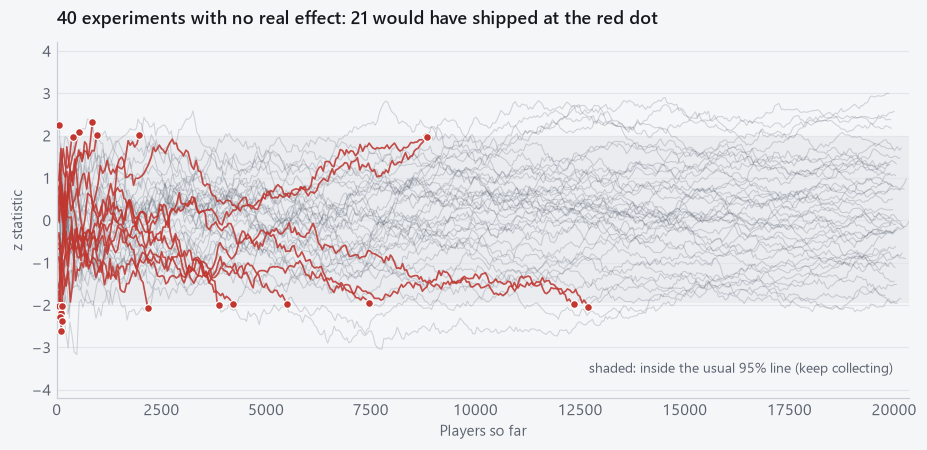

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
show_runs = 40
x = n_all[:show_runs]
ax.axhspan(-1.96, 1.96, color="#e2e5ea", alpha=0.55, lw=0, zorder=0)
for r in range(show_runs):
    ax.plot(x[r], Z[r], color=CONTROL, lw=0.7, alpha=0.22, zorder=1)  # the whole path, faint
    if ever[r]:  # in red up to the moment a peeker would have shipped, then stop
        k = first_look[r]
        ax.plot(x[r, : k + 1], Z[r, : k + 1], color=STOP, lw=1.1, alpha=0.85, zorder=2)
        ax.scatter(x[r, k], Z[r, k], s=26, color=STOP, zorder=3, edgecolor="white", linewidth=0.8)
ax.set_ylim(-4.2, 4.2)
ax.set_xlim(0, n_all[:show_runs, -1].max())
ax.set_xlabel("Players so far")
ax.set_ylabel("z statistic")
ax.text(n_all[0, -1] * 0.99, -3.6, "shaded: inside the usual 95% line (keep collecting)", ha="right", fontsize=9,
        color=MUTED)
n_red = int(ever[:show_runs].sum())
ax.set_title(f"{show_runs} experiments with no real effect: {n_red} would have shipped at the red dot")
savefig(fig, "02_z_paths")

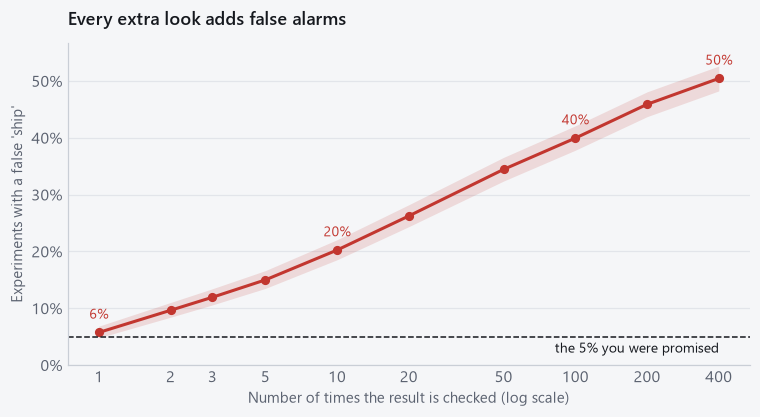

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(by_looks.index, by_looks.ci_low, by_looks.ci_high, color=STOP, alpha=0.15, lw=0)
ax.plot(by_looks.index, by_looks.rate, color=STOP, marker="o", ms=5)
ax.axhline(0.05, color=INK, ls="--", lw=1)
ax.text(400, 0.022, "the 5% you were promised", fontsize=9, color=INK, ha="right")
for k in [1, 10, 100, 400]:
    v = by_looks.loc[k, "rate"]
    ax.annotate(f"{v:.0%}", (k, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9,
                color=STOP)
ax.set_xscale("log")
ax.set_xticks(LOOKS, [str(k) for k in LOOKS])
ax.minorticks_off()
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, max(0.45, by_looks.ci_high.max() + 0.04))
ax.set_xlabel("Number of times the result is checked (log scale)")
ax.set_ylabel("Experiments with a false 'ship'")
ax.set_title("Every extra look adds false alarms")
savefig(fig, "02_false_alarms_by_looks")

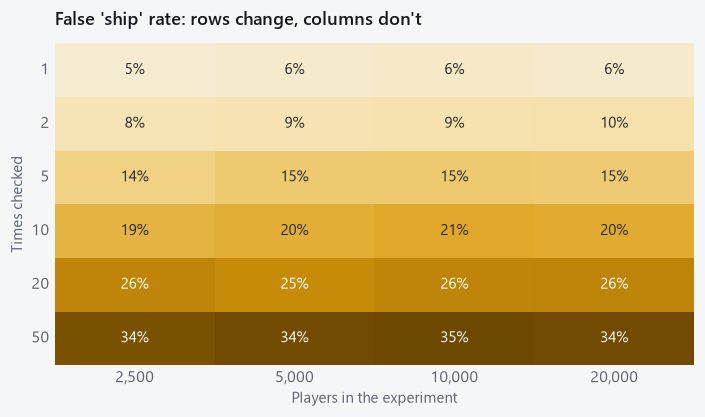

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.heatmap(grid, annot=True, fmt=".0%", cmap=GOLD_CMAP, vmin=0, vmax=0.35, cbar=False,
            annot_kws={"fontsize": 10}, ax=ax)
ax.set_xticklabels([f"{c:,}" for c in grid.columns])
ax.tick_params(axis="both", rotation=0)
ax.set_xlabel("Players in the experiment")
ax.set_ylabel("Times checked")
ax.set_title("False 'ship' rate: rows change, columns don't")
savefig(fig, "02_looks_vs_size_heatmap")

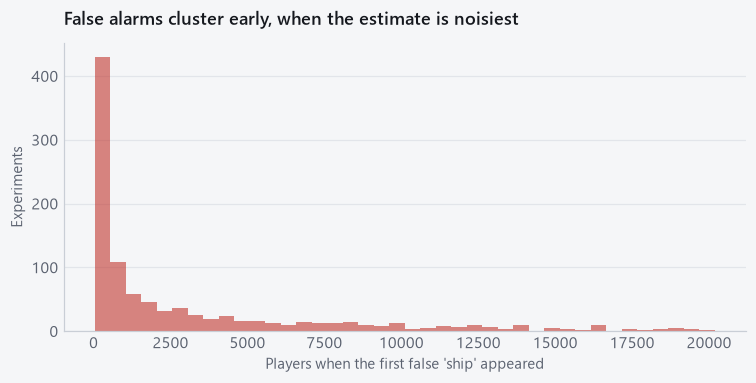

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.histplot(first_n[ever], bins=40, color=STOP, alpha=0.6, linewidth=0, ax=ax)
ax.set_xlabel("Players when the first false 'ship' appeared")
ax.set_ylabel("Experiments")
ax.set_title("False alarms cluster early, when the estimate is noisiest")
savefig(fig, "02_first_false_alarm")

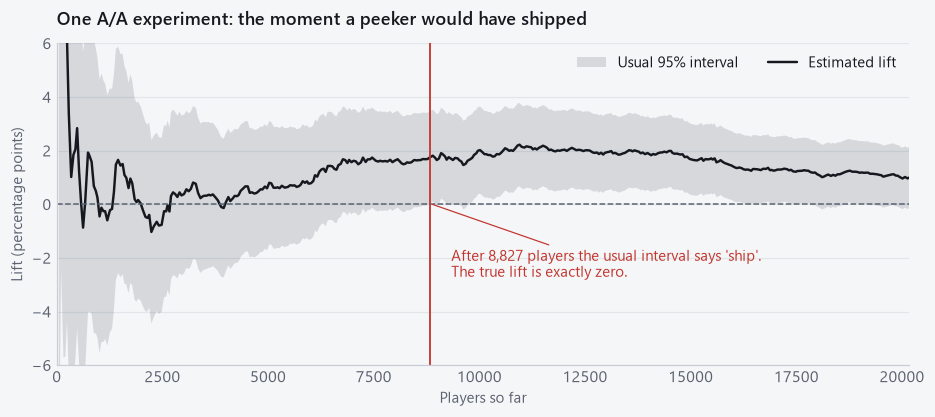

In [12]:
# One A/A experiment as the page would show it with the usual interval: the peeking counter.
r = int(np.argmax(ever & (first_look > 20) & (first_look < 200)))
k0 = first_look[r]
fig, ax = plt.subplots(figsize=(10, 3.8))
xs = n_all[r]
ax.fill_between(xs, (D[r] - 1.96 * SE[r]) * 100, (D[r] + 1.96 * SE[r]) * 100, color=CONTROL, alpha=0.18, lw=0,
                label="Usual 95% interval")
ax.plot(xs, D[r] * 100, color=INK, lw=1.6, label="Estimated lift")
ax.axhline(0, color=MUTED, ls="--", lw=1)
ax.axvline(xs[k0], color=STOP, lw=1.2)
ax.annotate(f"After {xs[k0]:,} players the usual interval says 'ship'.\nThe true lift is exactly zero.",
            (xs[k0], (D[r, k0] - 1.96 * SE[r, k0]) * 100), xytext=(14, -48), textcoords="offset points",
            fontsize=9.5, color=STOP, arrowprops=dict(arrowstyle="-", color=STOP, lw=0.8))
ax.set_ylim(-6, 6)
ax.set_xlim(0, xs[-1])
ax.set_xlabel("Players so far")
ax.set_ylabel("Lift (percentage points)")
ax.set_title("One A/A experiment: the moment a peeker would have shipped")
ax.legend(loc="upper right", ncols=2)
savefig(fig, "02_peeking_counter")

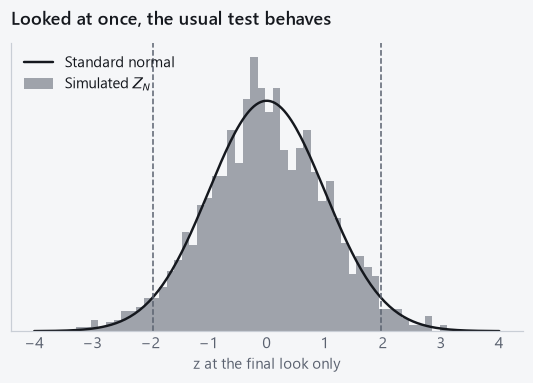

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.4))
sns.histplot(z_final, bins=50, stat="density", color=CONTROL, alpha=0.5, linewidth=0, ax=ax, label="Simulated $Z_N$")
zz = np.linspace(-4, 4, 200)
ax.plot(zz, norm.pdf(zz), color=INK, lw=1.6, label="Standard normal")
for v in (-1.96, 1.96):
    ax.axvline(v, color=MUTED, ls="--", lw=1)
ax.set_yticks([])
ax.set_ylabel("")
ax.set_xlabel("z at the final look only")
ax.set_title("Looked at once, the usual test behaves")
ax.legend(loc="upper left")
savefig(fig, "02_final_z_normal")

## 6. Results

In [14]:
once, every = rate_with_ci(np.abs(z_final) > 1.96), rate_with_ci(ever)
print(f"Look once at the end:     {once.rate:.1%}  (95% CI {once.ci_low:.1%} to {once.ci_high:.1%})")
print(f"Look after every batch:   {every.rate:.1%}  (95% CI {every.ci_low:.1%} to {every.ci_high:.1%})")
print(f"Median players at the first false alarm: {np.nanmedian(first_n):,.0f}")

Look once at the end:     5.8%  (95% CI 4.8% to 6.9%)
Look after every batch:   50.4%  (95% CI 48.3% to 52.6%)
Median players at the first false alarm: 800


- **Looking once works.** At the final look, the usual test raises a false alarm about 5% of the time, as promised, and $Z_N$ is standard normal.
- **Looking every batch does not.** Checked after each of 400 batches, the usual interval declares a winner in a large share of experiments where nothing works (see the table above). That share is the brief's validity evidence 3: the number the page shows next to the always-valid method.
- **More players doesn't fix it.** In the heatmap, the false-alarm rate changes down the rows (more looks) and barely across the columns (bigger experiments).
- **False alarms come early.** Most first crossings happen in the first few thousand players, which is exactly when a live page is most tempting to watch.

- **Design note for the page.** Many first crossings happen in the first few hundred players, where the normal approximation behind any z-based interval is shaky. Whatever method drives the verdict, the page should not show one before a minimum sample (to be set in notebook 04).

Notebook 03 replaces the fixed 1.96 with a boundary that widens just enough to make every look safe.

## 7. What gets promoted

| Function | Goes to | Guarded by |
|---|---|---|
| `naive_z` (estimate, SE, z from running totals) | `ablab/stats.py` | `tests/test_stats.py`: equals `statsmodels.test_proportions_2indep` (Wald) on fixtures |
| A/A peeking simulation | `validity/peeking.py`, writes `results/naive_peeking.json` | Evidence 3 in the brief; the page cites this file |

## 8. Production parity

`naive_z` now lives in `ablab/stats.py` (tested against `statsmodels` in `tests/test_stats.py`).

In [15]:
from ablab.stats import diff_in_proportions  # noqa: E402

d_prod, se_prod, z_prod = diff_in_proportions(s_t, n_t, s_c, n_c)
assert np.allclose(z_prod, Z) and np.allclose(se_prod, SE) and np.allclose(d_prod, D)
print("ablab.stats reproduces this notebook on all", Z.size, "experiment-looks")

ablab.stats reproduces this notebook on all 800000 experiment-looks


## Further reading

Why checking the usual interval at every update inflates false alarms. Where to find them: **[local]** = `docs/papers/` in this project (kept out of the repo) · **[Vega: folder]** = `Vega/paper-library/pdfs/<folder>/` (Vega's library also has text versions in `paper-library/md/` and notes in `paper-library/papers/`) · **[online]** = not in either library yet. ★ = read first.

Theory notes in this project: [anytime-valid](../docs/theory/anytime-valid.md), [sequential-chapter](../docs/theory/sequential-chapter.md).

- ★ Johari, R., Koomen, P., Pekelis, L., & Walsh, D. (2017). Peeking at A/B tests: why it matters, and what to do about it. *KDD 2017*. The paper that made peeking a household word in industry. **[Vega: 04-sequential-anytime-valid]** (journal version: *Operations Research* 70(3), 2022, https://doi.org/10.1287/opre.2021.2135)
- ★ Miller, E. *How Not To Run an A/B Test* (blog). The classic short explanation, with simulations. **[Vega: 04-sequential-anytime-valid]**
- Armitage, P., McPherson, C. K., & Rowe, B. C. (1969). Repeated significance tests on accumulating data. *JRSS-A* 132(2). The original result, from clinical trials. **[online]** https://doi.org/10.2307/2343787
- Etsy Engineering. *How Etsy Handles Peeking in A/B Testing* (blog). How a company actually deals with it. **[Vega: 04-sequential-anytime-valid]**
- Spotify Engineering. *Bringing Sequential Testing to Experiments with Longitudinal Data, Part 1: The Peeking Problem 2.0* (blog). Peeking when the same users are measured repeatedly. **[Vega: 04-sequential-anytime-valid]**
- Deng, A., Lu, J., & Chen, S. (2016). Continuous monitoring of A/B tests without pain: optional stopping in Bayesian testing. arXiv:1602.05549. Whether Bayesian tests escape the problem. **[Vega: 04-sequential-anytime-valid]**
- Robinson, D. *Is Bayesian A/B Testing Immune to Peeking? Not Exactly* (Variance Explained blog). The short answer to the above. **[Vega: 04-sequential-anytime-valid]**